# AI Jobs Data Cleaning

Cleaning `ai_jobs_market_2025_2026.csv` so it's ready for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('ai_jobs_market_2025_2026.csv')
df.head()

,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,ai_salary_premium_pct,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier
0,AIJOB0001,AI Agent Developer,AI Engineering,Senior (6-9 yrs),7,Master's,239000.0,155000,290000,Boston,...,13.1,96,16.9,6.8,2026,3,1,0,1,Senior ($200-300k)
1,AIJOB0002,Prompt Engineer,AI Engineering,Senior (6-9 yrs),2,Bachelor's,166000.0,90000,200000,London,...,5.4,82,11.6,6.2,2026,1,1,1,1,Upper-Mid ($150-200k)
2,AIJOB0003,LLM Engineer,AI Engineering,Senior (6-9 yrs),4,Associate's,360000.0,160000,300000,Seattle,...,9.1,98,42.7,7.7,2026,1,1,1,1,Elite (>$300k)
3,AIJOB0004,Data Engineer (AI),Data Engineering,Senior (6-9 yrs),3,Bachelor's,161000.0,130000,220000,Singapore,...,12.0,88,6.7,9.5,2026,3,1,1,0,Upper-Mid ($150-200k)
4,AIJOB0005,AI Product Manager,Product,Lead (10+ yrs),5,Bootcamp/Self-taught,283000.0,140000,260000,Los Angeles,...,9.4,85,17.3,8.9,2026,1,1,1,0,Senior ($200-300k)


## 1. Check the data

In [2]:
df.shape

(1500, 25)

In [3]:
# missing values and duplicate rows
print('missing:', df.isna().sum().sum())
print('duplicates:', df.duplicated().sum())
print('dup job ids:', df['job_id'].duplicated().sum())

missing: 0
duplicates: 0
dup job ids: 0


In [4]:
# salary should be between the min and max columns
bad_salary = df[(df['annual_salary_usd'] < df['salary_min_usd']) |
                (df['annual_salary_usd'] > df['salary_max_usd'])]
len(bad_salary)

288

In [5]:

def check_years(row):
    lvl = row['experience_level']
    yrs = row['years_of_experience']
    if lvl == 'Entry (0-2 yrs)':
        return 0 <= yrs <= 2
    if lvl == 'Mid (3-5 yrs)':
        return 3 <= yrs <= 5
    if lvl == 'Senior (6-9 yrs)':
        return 6 <= yrs <= 9
    return yrs >= 10  # Lead

ok_years = df.apply(check_years, axis=1)
print('years not matching level:', (~ok_years).sum())

years not matching level: 1099


In [6]:
# same skill written twice
def has_dup_skills(skills):
    parts = skills.split('|')
    return len(parts) != len(set(parts))

df['required_skills'].apply(has_dup_skills).sum()

np.int64(119)

## 2. Fix the problems

In [7]:
# remove repeated skills
def dedupe_skills(skills):
    seen = []
    for s in skills.split('|'):
        s = s.strip()
        if s not in seen:
            seen.append(s)
    return '|'.join(seen)

df['required_skills'] = df['required_skills'].apply(dedupe_skills)
df['skill_count'] = df['required_skills'].apply(lambda s: len(s.split('|')))

In [8]:

df['salary_min_usd'] = np.minimum(df['salary_min_usd'], df['annual_salary_usd'])
df['salary_max_usd'] = np.maximum(df['salary_max_usd'], df['annual_salary_usd'])
df['annual_salary_usd'] = df['annual_salary_usd'].astype(int)

In [9]:

low = df['experience_level'].map({'Entry (0-2 yrs)': 0, 'Mid (3-5 yrs)': 3,
                                 'Senior (6-9 yrs)': 6, 'Lead (10+ yrs)': 10})
high = df['experience_level'].map({'Entry (0-2 yrs)': 2, 'Mid (3-5 yrs)': 5,
                                  'Senior (6-9 yrs)': 9, 'Lead (10+ yrs)': 99})
df['years_of_experience'] = df['years_of_experience'].clip(low, high)

In [10]:

df['salary_tier'] = pd.cut(df['annual_salary_usd'],
                         bins=[0, 100000, 150000, 200000, 300000, np.inf],
                         labels=['Entry (<$100k)', 'Mid ($100-150k)',
                                 'Upper-Mid ($150-200k)', 'Senior ($200-300k)',
                                 'Elite (>$300k)'])

In [11]:

df['is_senior'] = df['is_senior'].astype(bool)
df['is_remote_friendly'] = df['is_remote_friendly'].astype(bool)
df['is_llm_role'] = df['is_llm_role'].astype(bool)

df['posting_date'] = pd.to_datetime(df['posting_year'].astype(str) + '-' +
                                  df['posting_month'].astype(str) + '-01')

In [12]:

df['experience_level'] = pd.Categorical(df['experience_level'],
    categories=['Entry (0-2 yrs)', 'Mid (3-5 yrs)', 'Senior (6-9 yrs)', 'Lead (10+ yrs)'],
    ordered=True)

df['remote_work'] = pd.Categorical(df['remote_work'],
    categories=['On-site', 'Hybrid', 'Fully Remote'], ordered=True)

df['company_size'] = pd.Categorical(df['company_size'],
    categories=['Startup (1-50)', 'SME (51-500)', 'Mid-size (501-5000)',
                'Enterprise (5000+)', 'Big Tech (FAANG+)'], ordered=True)

## 3. Check its all fixed

In [13]:
print('missing:', df.isna().sum().sum())
print('salary inside range:', ((df['annual_salary_usd'] >= df['salary_min_usd']) &
      (df['annual_salary_usd'] <= df['salary_max_usd'])).all())
print('years ok:', df.apply(check_years, axis=1).all())
print('dup skills left:', df['required_skills'].apply(has_dup_skills).sum())

missing: 0
salary inside range: True


years ok: True
dup skills left: 0


## 4. Save the clean file

In [14]:
df.to_csv('ai_jobs_cleaned.csv', index=False)

skills_long = df[['job_id', 'job_title', 'job_category', 'required_skills']].copy()
skills_long['skill'] = skills_long['required_skills'].str.split('|')
skills_long = skills_long.explode('skill').drop(columns='required_skills')
skills_long.to_csv('ai_jobs_skills_long.csv', index=False)

df.head()

,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier,skill_count,posting_date
0,AIJOB0001,AI Agent Developer,AI Engineering,Senior (6-9 yrs),7,Master's,239000,155000.0,290000.0,Boston,...,16.9,6.8,2026,3,True,False,True,Senior ($200-300k),6,2026-03-01
1,AIJOB0002,Prompt Engineer,AI Engineering,Senior (6-9 yrs),6,Bachelor's,166000,90000.0,200000.0,London,...,11.6,6.2,2026,1,True,True,True,Upper-Mid ($150-200k),7,2026-01-01
2,AIJOB0003,LLM Engineer,AI Engineering,Senior (6-9 yrs),6,Associate's,360000,160000.0,360000.0,Seattle,...,42.7,7.7,2026,1,True,True,True,Elite (>$300k),5,2026-01-01
3,AIJOB0004,Data Engineer (AI),Data Engineering,Senior (6-9 yrs),6,Bachelor's,161000,130000.0,220000.0,Singapore,...,6.7,9.5,2026,3,True,True,False,Upper-Mid ($150-200k),9,2026-03-01
4,AIJOB0005,AI Product Manager,Product,Lead (10+ yrs),10,Bootcamp/Self-taught,283000,140000.0,283000.0,Los Angeles,...,17.3,8.9,2026,1,True,True,False,Senior ($200-300k),6,2026-01-01


## 5. Graphs

In [15]:
import os
os.makedirs('Graphs', exist_ok=True)

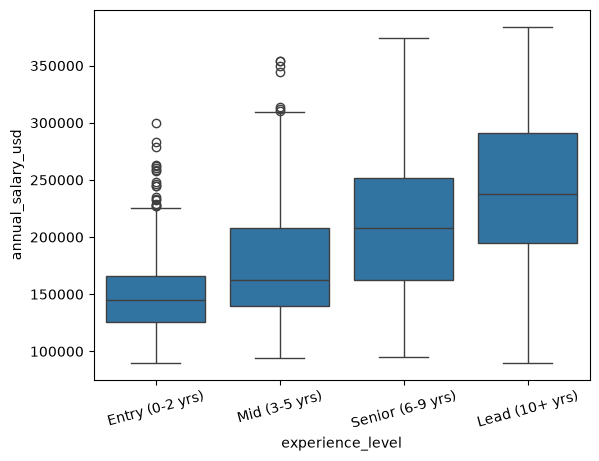

In [16]:
# box plot - salary by experience level
sns.boxplot(data=df, x='experience_level', y='annual_salary_usd')
plt.xticks(rotation=15)
plt.savefig('Graphs/salary_by_experience.png')
plt.show()

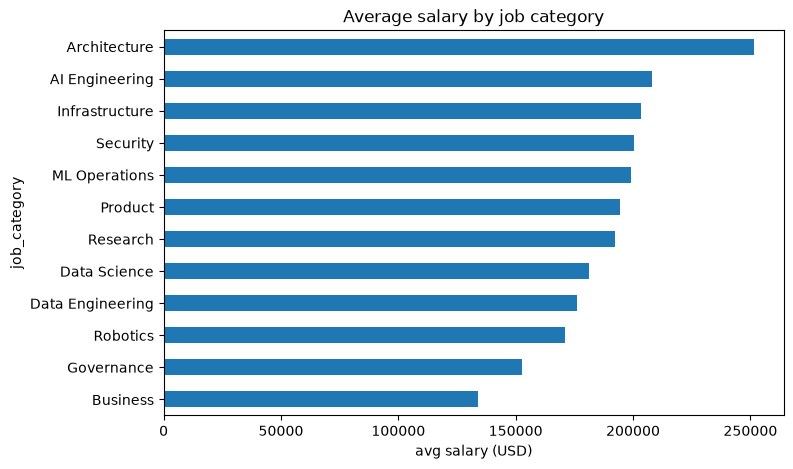

In [17]:
# bar chart - average salary for each job category
avg_salary = df.groupby('job_category')['annual_salary_usd'].mean().sort_values()

avg_salary.plot(kind='barh', figsize=(8, 5))
plt.title('Average salary by job category')
plt.xlabel('avg salary (USD)')
plt.savefig('Graphs/avg_salary_by_category.png')
plt.show()

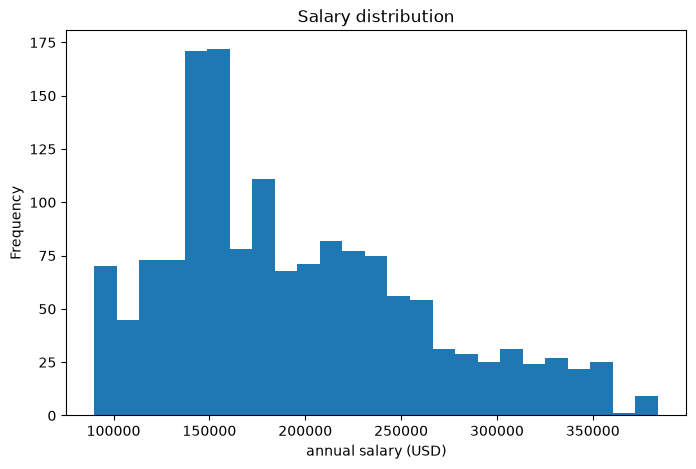

In [18]:
# histogram - how the salaries are spread out
df['annual_salary_usd'].plot(kind='hist', bins=25, figsize=(8, 5))
plt.title('Salary distribution')
plt.xlabel('annual salary (USD)')
plt.savefig('Graphs/salary_distribution.png')
plt.show()

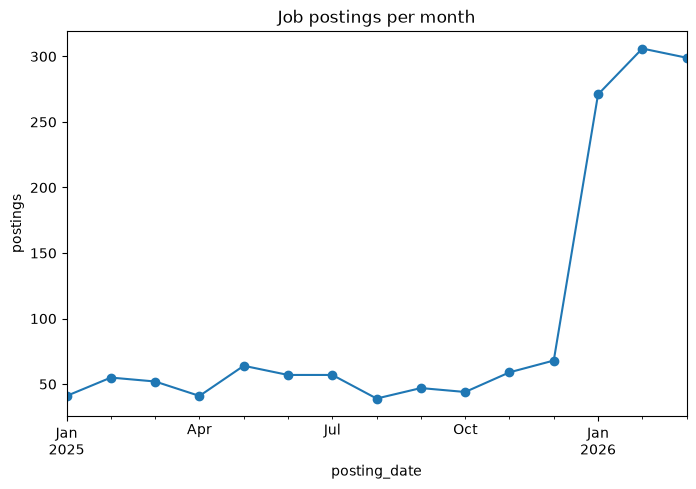

In [19]:
# line chart - job postings per month
monthly = df.groupby('posting_date').size()

monthly.plot(marker='o', figsize=(8, 5))
plt.title('Job postings per month')
plt.ylabel('postings')
plt.savefig('Graphs/postings_per_month.png')
plt.show()

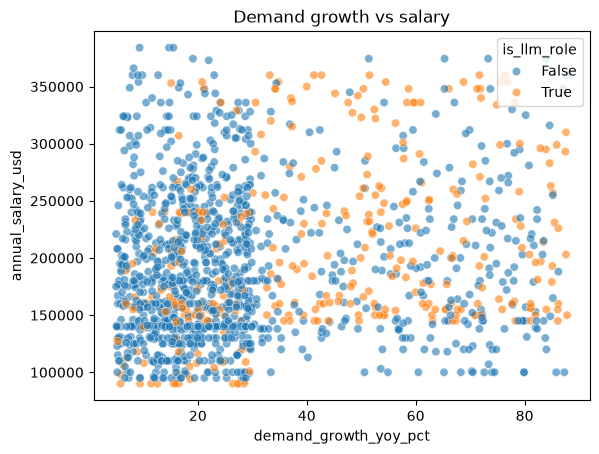

In [20]:
# scatter plot - does faster growing demand mean higher pay?
sns.scatterplot(data=df, x='demand_growth_yoy_pct', y='annual_salary_usd',
                hue='is_llm_role', alpha=0.6)
plt.title('Demand growth vs salary')
plt.savefig('Graphs/growth_vs_salary.png')
plt.show()